##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 02 — Target creation

The single most important rule in this pipeline:

> **Features from month M predict the case count in month M+1.**

Get this wrong (e.g. accidentally include same-month information) and your
offline metrics will look great while the model is operationally useless,
because in production you never have next month's data when you need the
prediction. This notebook builds the shifted target **and proves, by hand,
that the shift is correct** for a sample hexagon.

## Prerequisites
- `artifacts/features.csv` from notebook `01`


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import SAMPLE_DATA_DIR, ARTIFACTS_DIR, load_data, save_data

patients = load_data(SAMPLE_DATA_DIR / "patients.csv")
patients["diagnosis_date"] = pd.to_datetime(patients["diagnosis_date"])
features = load_data(ARTIFACTS_DIR / "features.csv")
features["month"] = pd.to_datetime(features["month"])
print(f"features: {features.shape}  |  patients: {len(patients)}")


features: (6000, 29)  |  patients: 6795


## Target definitions

| Column | Meaning | Used for |
| --- | --- | --- |
| `target_cases` | Case count in month **M+1** (0, 1, 2, ...) | Stage-2 Poisson regressor |
| `has_any_cases` | `1` if `target_cases > 0` | Stage-1 gate classifier |
| `is_cluster` | `1` if `target_cases >= 3` | Backward-compat with binary-threshold approaches |
| `is_emerging` | `1` if currently quiet (<=1 case) but jumps to >=2 next month | Cold-start / early-outbreak analysis |


In [3]:
from pipeline.targets import create_future_target

labeled = create_future_target(features, patients)
save_data(labeled, ARTIFACTS_DIR / "labeled.csv")
print(f"{len(labeled)} labeled hexagon-months (one fewer month per hexagon than features, by design)")
labeled[["h3_index", "month", "target_month", "total_cases", "target_cases", "has_any_cases", "is_cluster", "is_emerging"]].head()


INFO | Targets: 5700 rows | positive hex-months: 3581 (62.8%)


INFO | Saved 5700 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/labeled.csv


5700 labeled hexagon-months (one fewer month per hexagon than features, by design)


,h3_index,month,target_month,total_cases,target_cases,has_any_cases,is_cluster,is_emerging
0,8a60885010c7fff,2024-01-01,2024-02-01,0.0,3,1,1,1
1,8a60885010c7fff,2024-02-01,2024-03-01,3.0,2,1,0,0
2,8a60885010c7fff,2024-03-01,2024-04-01,2.0,2,1,0,0
3,8a60885010c7fff,2024-04-01,2024-05-01,2.0,0,0,0,0
4,8a60885010c7fff,2024-05-01,2024-06-01,0.0,2,1,0,1


## Manual verification on one hexagon

Don't trust the function -- check it. Pick the busiest hexagon and manually
recompute next month's case count from the raw patient list, then compare
against what `create_future_target` produced.


In [4]:
busy_hex = features.loc[features["total_cases"].idxmax(), "h3_index"]
example = labeled[labeled["h3_index"] == busy_hex].sort_values("month")
print(f"Hexagon: {busy_hex}\n")
for _, row in example.iterrows():
    manual_count = len(patients[
        (patients["h3_index"] == busy_hex) &
        (patients["diagnosis_date"].dt.to_period("M").dt.to_timestamp() == row["target_month"])
    ])
    status = "OK" if manual_count == row["target_cases"] else "MISMATCH"
    print(f"  month={row['month'].date()}  target_month={row['target_month'].date()}  "
          f"pipeline target_cases={int(row['target_cases'])}  manual recount={manual_count}  [{status}]")


Hexagon: 8a608850e94ffff

  month=2024-01-01  target_month=2024-02-01  pipeline target_cases=6  manual recount=6  [OK]
  month=2024-02-01  target_month=2024-03-01  pipeline target_cases=3  manual recount=3  [OK]
  month=2024-03-01  target_month=2024-04-01  pipeline target_cases=1  manual recount=1  [OK]
  month=2024-04-01  target_month=2024-05-01  pipeline target_cases=0  manual recount=0  [OK]
  month=2024-05-01  target_month=2024-06-01  pipeline target_cases=0  manual recount=0  [OK]
  month=2024-06-01  target_month=2024-07-01  pipeline target_cases=8  manual recount=8  [OK]
  month=2024-07-01  target_month=2024-08-01  pipeline target_cases=0  manual recount=0  [OK]
  month=2024-08-01  target_month=2024-09-01  pipeline target_cases=3  manual recount=3  [OK]
  month=2024-09-01  target_month=2024-10-01  pipeline target_cases=3  manual recount=3  [OK]
  month=2024-10-01  target_month=2024-11-01  pipeline target_cases=0  manual recount=0  [OK]
  month=2024-11-01  target_month=2024-12-01 

## Class balance

TB hotspot prediction is a **rare-event** problem: most hexagon-months have
zero future cases. This is exactly why the model is two-stage (a gate
classifier handles the zero/non-zero split, and a Poisson regressor handles
"how many" only on the cases that matter).


Positive rate (has_any_cases=1): 62.8%  (3581 of 5700 hexagon-months)


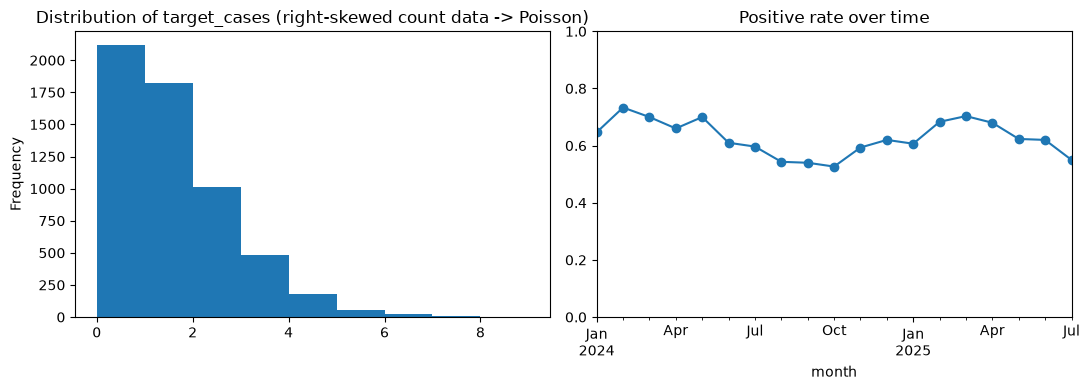

In [5]:
rate = labeled["has_any_cases"].mean()
print(f"Positive rate (has_any_cases=1): {rate*100:.1f}%  "
      f"({labeled['has_any_cases'].sum()} of {len(labeled)} hexagon-months)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labeled["target_cases"].plot(kind="hist", bins=range(0, int(labeled["target_cases"].max()) + 2), ax=axes[0])
axes[0].set_title("Distribution of target_cases (right-skewed count data -> Poisson)")
labeled.groupby("month")["has_any_cases"].mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Positive rate over time")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()
